# 06. H1b — анализ: зависит ли эффект соседей от позиции целевого

В H1 эффект «больше токсичных соседей → реже TOXIC» был слабым на позиции 1 и сильным на позициях 5 и 9, но позиция была связана с повтором. Здесь позиция скрещена с долей соседей, а соседи в тройке одни и те же.

**Что смотрим**
1. Доля ответов TOXIC по позиции и доле токсичных соседей.
2. Наклон (0 → 100 %) отдельно для каждой позиции, GEE с кластерами по целевому.
3. **Взаимодействие** `доля_токсичных × позиция`: значимо ли различается наклон между позициями.
4. Главный эффект позиции при 0 % токсичных соседей: сам по себе влияет ли место в списке.

Сравнивать нужно с **той же** выборкой и моделью, что в H1.

In [1]:
MODEL_KEY = "gigachat_lite"
LANG = "en"
PILOT = False

In [2]:
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd()
DATA_PROC = PROJECT_DIR / "data" / "processed"
DATA_RES = PROJECT_DIR / "data" / "results"
FIG_DIR = PROJECT_DIR / "data" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

suffix = f"{MODEL_KEY}_{LANG}" + ("_pilot" if PILOT else "")
targets = pd.read_parquet(DATA_PROC / "targets.parquet").set_index("id")
b = pd.read_parquet(DATA_RES / f"h1b_batches_{suffix}.parquet")

sp = DATA_RES / f"h1_singles_{MODEL_KEY}_{LANG}.parquet"
if not sp.exists():
    sp = DATA_RES / f"h1_singles_{MODEL_KEY}_{LANG}_pilot.parquet"
s = pd.read_parquet(sp)
print("одиночные из:", sp.name)

df = b.merge(s[["id", "y_single"]], left_on="target_id", right_on="id").drop(columns="id")
df["gold"] = df["target_id"].map(targets["label"])
df["target_group"] = df["target_id"].map(targets["target_group"])
df = df.dropna(subset=["y_batch", "y_single"]).sort_values("target_id")
print(len(df), "строк;", df["target_id"].nunique(), "целевых")

одиночные из: h1_singles_gigachat_lite_en.parquet
2700 строк; 300 целевых


## 1. Доля ответов TOXIC по позиции и уровню

In [3]:
tab = df.groupby(["target_pos", "prop_toxic"])["y_batch"].mean().unstack().round(3)
tab["разница 100%−0%, п.п."] = ((tab[1.0] - tab[0.0]) * 100).round(1)
print("Доля TOXIC у целевого (одиночно:", round(df.drop_duplicates("target_id")["y_single"].mean(), 3), ")")
tab

Доля TOXIC у целевого (одиночно: 0.59 )


prop_toxic,0.0,0.5,1.0,"разница 100%−0%, п.п."
target_pos,,,,
1,0.660,0.663,0.653,-0.7
5,0.617,0.487,0.427,-19.0
9,0.593,0.520,0.523,-7.0


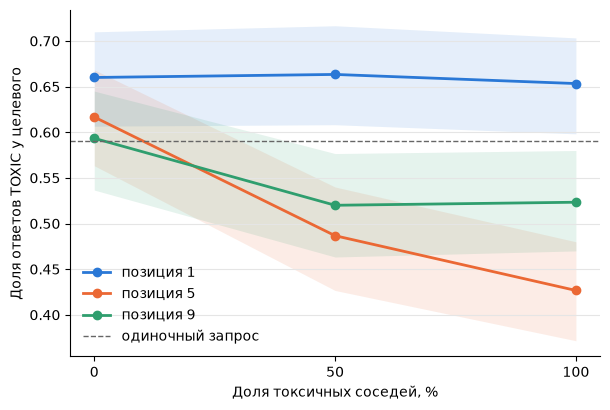

In [4]:
COL = {1: "#2a78d6", 5: "#eb6834", 9: "#2f9e6e"}
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for pos, g in df.groupby("target_pos"):
    per = g.groupby(["target_id", "prop_toxic"])["y_batch"].mean().unstack()
    m = per.mean()
    rng = np.random.default_rng(0)
    boots = np.array([per.sample(len(per), replace=True, random_state=int(rng.integers(1e9))).mean().to_numpy() for _ in range(500)])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    x = m.index.to_numpy() * 100
    ax.plot(x, m.to_numpy(), marker="o", lw=2, color=COL[pos], label=f"позиция {pos}")
    ax.fill_between(x, lo, hi, color=COL[pos], alpha=0.12, lw=0)
ax.axhline(df.drop_duplicates("target_id")["y_single"].mean(), color="#666", ls="--", lw=1, label="одиночный запрос")
ax.set_xlabel("Доля токсичных соседей, %"); ax.set_ylabel("Доля ответов TOXIC у целевого")
ax.set_xticks([0, 50, 100]); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / f"h1b_position_{suffix}.png", dpi=150); plt.show()

## 2. Наклон по позициям (GEE, п.п. при переходе 0 → 100 %)
Для каждой позиции отдельно: `y_batch ~ prop_toxic + y_single`, кластеры — целевые.

In [5]:
rows = []
for pos, g in df.groupby("target_pos"):
    m = smf.gee("y_batch ~ prop_toxic + y_single", groups="target_id", data=g,
                cov_struct=sm.cov_struct.Exchangeable()).fit()
    ci = m.conf_int().loc["prop_toxic"]
    rows.append(dict(position=pos, n_targets=g["target_id"].nunique(), slope_pp=100 * m.params["prop_toxic"],
                     ci_low=100 * ci[0], ci_high=100 * ci[1], p=m.pvalues["prop_toxic"]))
pd.DataFrame(rows).round(4)

,position,n_targets,slope_pp,ci_low,ci_high,p
0,1,300,-0.6667,-3.1100,1.7767,0.5928
1,5,300,-19.0000,-24.0678,-13.9322,0.0000
2,9,300,-7.0000,-11.5979,-2.4021,0.0028


## 3. Взаимодействие «доля токсичных × позиция» и главный эффект позиции
Одна модель: `y_batch ~ prop_toxic * C(target_pos) + y_single`. Положительный коэффициент взаимодействия означает, что наклон на этой позиции менее отрицательный, чем на позиции 1.
Блок «Wald» — совместный тест, что наклоны на всех позициях одинаковы.

In [6]:
m = smf.gee("y_batch ~ prop_toxic * C(target_pos) + y_single", groups="target_id", data=df,
            cov_struct=sm.cov_struct.Exchangeable()).fit()
out = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues}).round(4)
print(out.to_string())
names = list(m.params.index)
inter = [n for n in names if n.startswith("prop_toxic:")]
R = np.zeros((len(inter), len(names)))
for i, n in enumerate(inter):
    R[i, names.index(n)] = 1
w = m.wald_test(R, scalar=True)
print(f"\nWald-тест равенства наклонов по позициям: chi2 = {float(w.statistic):.2f}, p = {float(w.pvalue):.4g}")
main = [n for n in names if n.startswith("C(target_pos)")]
R2 = np.zeros((len(main), len(names)))
for i, n in enumerate(main):
    R2[i, names.index(n)] = 1
w2 = m.wald_test(R2, scalar=True)
print(f"Wald-тест главного эффекта позиции (при 0 % токсичных соседей): chi2 = {float(w2.statistic):.2f}, p = {float(w2.pvalue):.4g}")

                                 coef      se       p
Intercept                      0.2741  0.0287  0.0000
C(target_pos)[T.5]            -0.0572  0.0202  0.0046
C(target_pos)[T.9]            -0.0817  0.0222  0.0002
prop_toxic                    -0.0067  0.0125  0.5928
prop_toxic:C(target_pos)[T.5] -0.1833  0.0273  0.0000
prop_toxic:C(target_pos)[T.9] -0.0633  0.0253  0.0124
y_single                       0.6578  0.0294  0.0000

Wald-тест равенства наклонов по позициям: chi2 = 45.37, p = 1.406e-10
Wald-тест главного эффекта позиции (при 0 % токсичных соседей): chi2 = 13.81, p = 0.001004


## Как читать
* **Наклоны разные, Wald p < 0,05** — эффект соседей действительно зависит от позиции; при независимом от повтора дизайне это уже не артефакт набора соседей.
* **Наклоны примерно равны** — различия по позиции в H1 объяснялись разными наборами соседей, а не позицией.
* **Главный эффект позиции значим** — даже без токсичных соседей место в списке меняет ответ.
* Если выборка пилотная (20 целевых), доверительные интервалы будут широкими — для выводов нужен полный прогон.